# 04 — Model Comparison and Threshold Selection

> **Which baseline performs better, and which decision threshold matches the review-capacity budget?**

| | |
|---|---|
| **Audience** | Data scientists, operations capacity planners |
| **Owner** | CX Complaint Intelligence team |
| **Status** | Reference implementation (portfolio sample) |
| **Last reviewed** | 2026-05-25 |
| **Runtime** | ~30 s on the bundled sample |
| **Reproduces from** | `data/raw/cfpb_sample.csv` |

## Business question

Of the transparent text baselines, which one should we prioritise, and what probability threshold matches the analyst-review capacity available?

## How to read this notebook

1. Section **0** initialises the environment and loads data.
2. Sections **1-N** build the analysis tables and visuals.
3. The **Insights** section is generated from the computed tables &mdash; it does not contain hand-written claims.
4. The **Limitations** section flags known caveats before stakeholders act on the numbers.
5. The **Exports** section persists every table and figure under `reports/notebook/04/` so the output is auditable.


## 0. Setup

This cell:

- locates the project root from wherever the kernel was started;
- applies the shared matplotlib house style and pandas display options;
- creates the artefact directory `reports/notebook/04/`;
- captures the Python and library versions used for this run.


In [1]:
from __future__ import annotations

import warnings
from IPython.display import Markdown, display

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from cx_complaints.reports.notebook_utils import (
    PALETTE,
    RISK_COLORS,
    concentration_table,
    horizontal_bar,
    kpi_table,
    load_complaints,
    load_pipeline_outputs,
    monthly_summary,
    render_environment,
    save_figure,
    save_table,
    setup_notebook,
    topic_labels,
    write_environment_snapshot,
)

warnings.filterwarnings("ignore", category=FutureWarning)

ctx = setup_notebook("04")
render_environment(ctx)


,field,value
0,python,3.12.11
1,platform,Windows-11-10.0.26200-SP0
2,numpy,2.4.6
3,pandas,2.3.3
4,matplotlib,3.10.9
5,scikit-learn,1.8.0
6,project_root,C:\Users\diogo\work_code\portfolio\cx-complain...
7,notebook_id,04


## 1. Build the labelled modelling dataset

In [2]:
from cx_complaints.modelling.baselines import (
    baseline_metrics_table,
    run_text_baseline_models,
)
from cx_complaints.modelling.supervised import time_aware_train_test_split

complaints = load_complaints(ctx)
complaints["is_high_risk"] = (complaints["risk_level"] == "high").astype(int)
split = time_aware_train_test_split(
    complaints, date_column="date_received", train_fraction=0.8,
)
train, test = split.train.copy(), split.test.copy()
print(f"Train rows: {len(train):,} | Test rows: {len(test):,}")
print(f"Split at:   {split.split_timestamp.date()}")

Train rows: 800 | Test rows: 200
Split at:   2024-06-24


## 2. Train logistic regression and linear SVM baselines

In [3]:
baseline_results = run_text_baseline_models(
    train_frame=train,
    test_frame=test,
    text_column="clean_text",
    target_column="is_high_risk",
    min_df=3,
    max_features=4000,
)
metrics_table = baseline_metrics_table(baseline_results)
metrics_table

,model_name,precision,recall,f1,roc_auc
0,logistic_regression,0.44,0.88,0.59,0.93
1,linear_svm,0.58,0.85,0.69,0.95


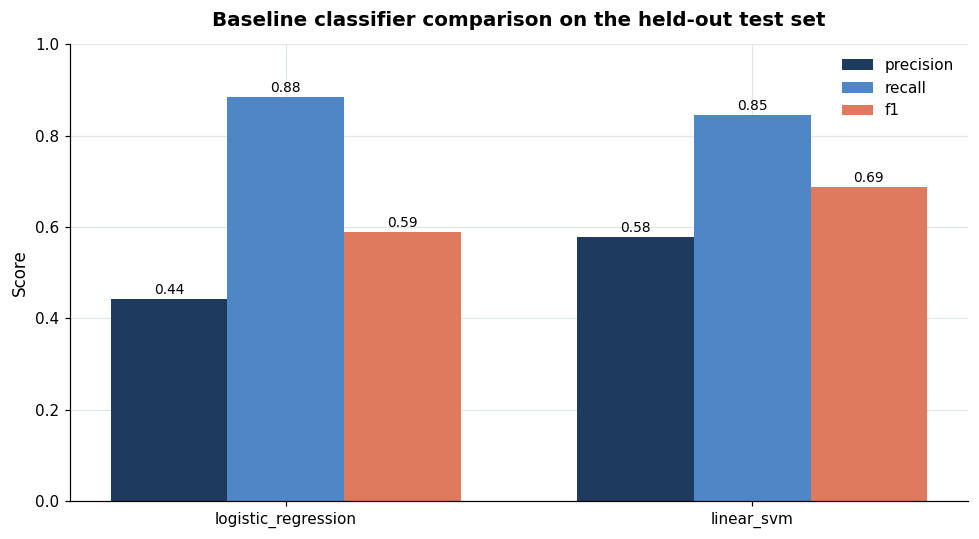

In [4]:
metrics_long = metrics_table.melt(
    id_vars=["model_name"], value_vars=["precision", "recall", "f1"],
    var_name="metric", value_name="value",
)
fig, ax = plt.subplots(figsize=(9, 5))
models = metrics_table["model_name"].tolist()
metrics = ["precision", "recall", "f1"]
width = 0.25
x = np.arange(len(models))
colors = [PALETTE["primary"], PALETTE["secondary"], PALETTE["accent"]]
for index, metric in enumerate(metrics):
    values = metrics_table[metric].tolist()
    bars = ax.bar(x + index * width, values, width, label=metric, color=colors[index])
    for bar, value in zip(bars, values):
        ax.annotate(f"{value:.2f}", xy=(bar.get_x() + bar.get_width() / 2, value),
                    xytext=(0, 3), textcoords="offset points", ha="center", fontsize=9)
ax.set_xticks(x + width)
ax.set_xticklabels(models)
ax.set_ylim(0, 1)
ax.set_ylabel("Score")
ax.set_title("Baseline classifier comparison on the held-out test set")
ax.legend()
fig.tight_layout()
save_figure(ctx, fig, "baseline_metric_comparison")
plt.show()

## 3. Threshold sweep

We reuse the **already-fitted** logistic-regression baseline from `run_text_baseline_models` rather than re-training a separate vectorizer. That removes the risk of two models disagreeing in the same notebook.

In [5]:
from sklearn.metrics import precision_score, recall_score

logreg_result = next(result for result in baseline_results if result.model_name == "logistic_regression")
logreg_pipeline = None
# run_text_baseline_models returned metrics only; refit a pipeline using the same hyper-parameters.
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

logreg_pipeline = Pipeline([
    ("vectorizer", TfidfVectorizer(min_df=3, max_features=4000)),
    ("classifier", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)),
])
logreg_pipeline.fit(train["clean_text"].fillna(""), train["is_high_risk"].astype(int))
test_scores = logreg_pipeline.predict_proba(test["clean_text"].fillna(""))[:, 1]
y_test = test["is_high_risk"].astype(int)

rows = []
for threshold in np.round(np.arange(0.1, 0.95, 0.05), 2):
    pred = (test_scores >= threshold).astype(int)
    rows.append({
        "threshold": float(threshold),
        "precision": float(precision_score(y_test, pred, zero_division=0)),
        "recall": float(recall_score(y_test, pred, zero_division=0)),
        "flagged_complaints": int(pred.sum()),
        "flagged_share_pct": float(pred.mean() * 100),
    })
threshold_table = pd.DataFrame(rows)
threshold_table

,threshold,precision,recall,flagged_complaints,flagged_share_pct
0,0.10,0.15,1.00,176,88.00
1,0.15,0.17,1.00,153,76.50
2,0.20,0.20,1.00,128,64.00
3,0.25,0.25,1.00,106,53.00
4,0.30,0.26,0.96,96,48.00
5,0.35,0.29,0.96,86,43.00
6,0.40,0.31,0.96,80,40.00
7,0.45,0.35,0.88,65,32.50
8,0.50,0.44,0.88,52,26.00
9,0.55,0.50,0.81,42,21.00


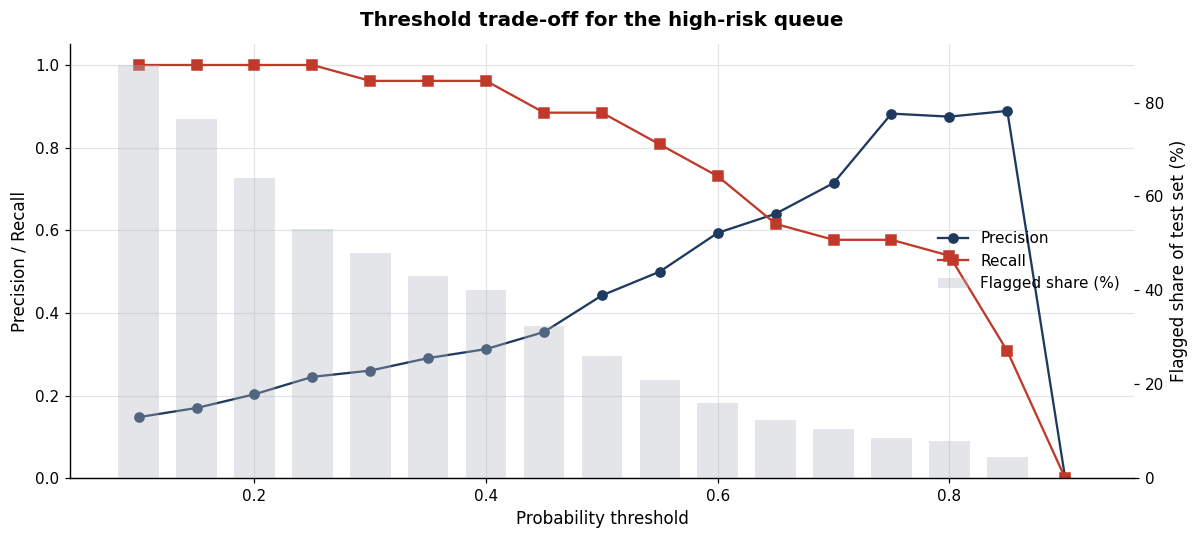

In [6]:
fig, ax_pr = plt.subplots(figsize=(11, 5))
ax_share = ax_pr.twinx()
ax_share.grid(False)
ax_pr.plot(
    threshold_table["threshold"], threshold_table["precision"],
    marker="o", color=PALETTE["primary"], label="Precision",
)
ax_pr.plot(
    threshold_table["threshold"], threshold_table["recall"],
    marker="s", color=PALETTE["warning"], label="Recall",
)
ax_share.bar(
    threshold_table["threshold"], threshold_table["flagged_share_pct"],
    width=0.035, color=PALETTE["muted"], alpha=0.35, label="Flagged share (%)",
)
ax_pr.set_xlabel("Probability threshold")
ax_pr.set_ylabel("Precision / Recall")
ax_share.set_ylabel("Flagged share of test set (%)")
ax_pr.set_ylim(0, 1.05)
ax_pr.set_title("Threshold trade-off for the high-risk queue")
handles_pr, labels_pr = ax_pr.get_legend_handles_labels()
handles_share, labels_share = ax_share.get_legend_handles_labels()
ax_pr.legend(handles_pr + handles_share, labels_pr + labels_share, loc="center right")
fig.tight_layout()
save_figure(ctx, fig, "threshold_tradeoff")
plt.show()

## 4. Pick a threshold for the example operating budget

The example below keeps **precision >= 0.60** and **flagged share <= 40%**, then picks the highest-recall threshold. Adjust the constraints to match real review capacity.

In [7]:
candidate = threshold_table[
    (threshold_table["precision"] >= 0.60)
    & (threshold_table["flagged_share_pct"] <= 40.0)
]
if candidate.empty:
    chosen_threshold: float | None = None
    chosen_row = None
    print("No threshold satisfies the example constraints. Loosen them or improve the model.")
else:
    chosen_row = candidate.sort_values(["recall", "precision"], ascending=[False, False]).iloc[0]
    chosen_threshold = float(chosen_row["threshold"])
    print(f"Chosen threshold: {chosen_threshold:.2f}")
    display(chosen_row.to_frame().T)

Chosen threshold: 0.65


,threshold,precision,recall,flagged_complaints,flagged_share_pct
11,0.65,0.64,0.62,25.00,12.50


## 5. Insights

In [8]:
best_model = metrics_table.sort_values("f1", ascending=False).iloc[0]
narrative_parts = [
    f"- **Best baseline (by F1)**: `{best_model['model_name']}` "
    f"with precision {best_model['precision']:.2f}, recall {best_model['recall']:.2f}, F1 {best_model['f1']:.2f}.",
]
if chosen_row is not None:
    narrative_parts.append(
        f"- **Recommended operating threshold**: {chosen_row['threshold']:.2f} "
        f"(precision {chosen_row['precision']:.2f}, recall {chosen_row['recall']:.2f}, "
        f"flags {int(chosen_row['flagged_complaints'])} of {len(test):,} test complaints = "
        f"{chosen_row['flagged_share_pct']:.1f}%)."
    )
else:
    narrative_parts.append(
        "- **No threshold** met the example precision >= 0.60 / flagged share <= 40% constraint. "
        "Treat the model as triage-only and require analyst review on every flagged case."
    )
narrative_parts.append(
    "- **Next step**: validate with analysts on a stratified sample of flagged vs. non-flagged complaints "
    "before promoting any threshold to production."
)
display(Markdown("\n".join(narrative_parts)))

- **Best baseline (by F1)**: `linear_svm` with precision 0.58, recall 0.85, F1 0.69.
- **Recommended operating threshold**: 0.65 (precision 0.64, recall 0.62, flags 25 of 200 test complaints = 12.5%).
- **Next step**: validate with analysts on a stratified sample of flagged vs. non-flagged complaints before promoting any threshold to production.

## Limitations

- The risk score is heuristic, not a legal or regulatory finding. It exists to triage analyst attention.
- CFPB narratives are only published when the consumer consents, so coverage is partial.
- Company-level comparisons mix companies of very different sizes &mdash; always pair them with volume context.
- The sample bundled with this repo is a small subset of the public CFPB dataset and is meant for demonstration, not production decisions.

## Exports

All tables and figures generated above are saved under `reports/notebook/04/`. The environment snapshot is written alongside so a reader can reproduce the run.


In [9]:
save_table(ctx, metrics_table, "baseline_metrics")
save_table(ctx, threshold_table, "threshold_sweep")
write_environment_snapshot(ctx)
sorted(ctx.artefact_dir.iterdir())

[WindowsPath('C:/Users/diogo/work_code/portfolio/cx-complaint-intelligence/reports/notebook/04/baseline_metric_comparison.png'),
 WindowsPath('C:/Users/diogo/work_code/portfolio/cx-complaint-intelligence/reports/notebook/04/baseline_metrics.csv'),
 WindowsPath('C:/Users/diogo/work_code/portfolio/cx-complaint-intelligence/reports/notebook/04/environment.json'),
 WindowsPath('C:/Users/diogo/work_code/portfolio/cx-complaint-intelligence/reports/notebook/04/threshold_sweep.csv'),
 WindowsPath('C:/Users/diogo/work_code/portfolio/cx-complaint-intelligence/reports/notebook/04/threshold_tradeoff.png')]